# Burn Severity Assessment of the 2024 Varnavas Wildfire, Attica, Greece

## Earth Observation Decision Intelligence with Sentinel-2

This notebook assesses the spatial impact and burn severity of the August 2024 wildfire in northeastern Attica, Greece, using multi-temporal Sentinel-2 Level-2A imagery.

The analysis retrieves real satellite imagery through a STAC-based data backend, applies cloud and quality masking, computes vegetation- and fire-sensitive spectral indices, analyses their temporal evolution, and derives spatial burn-severity products.

### Decision question

**Which areas affected by the August 2024 wildfire experienced the greatest vegetation damage and should be prioritised for post-fire field assessment?**

The intended users are forest-management and environmental-restoration authorities responsible for prioritising post-fire field inspections and recovery actions.

### Data and processing approach

- **Satellite mission:** Sentinel-2
- **Product:** Level-2A surface reflectance
- **Data backend:** Microsoft Planetary Computer STAC API
- **Primary indices:** NDVI and NBR
- **Change metric:** differenced Normalized Burn Ratio (dNBR)
- **Core outputs:** RGB imagery, spectral-index time series, burn-severity GeoTIFF, priority-area GeoJSON, and a decision-ready summary

## 1. Setup and Study Configuration

The analysis uses a Python geospatial stack for STAC catalogue access, raster processing, vector analysis, visualisation, and export. All processing is performed on actual Sentinel-2 pixel data rather than server-side summary statistics.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import geopandas as gpd
import rasterio
import rioxarray
import folium
import planetary_computer
import stackstac

from shapely.geometry import box, mapping
from pystac_client import Client
from rasterio.enums import Resampling
from rasterio.features import shapes as rio_shapes
from shapely.geometry import shape as shapely_shape

print("Environment ready.")

Environment ready.


## 2. Study Area and Wildfire Event

The case study focuses on the wildfire that started near Varnavas in northeastern Attica, Greece, on 11 August 2024 and subsequently spread across a large part of northeastern Attica.

A rectangular Area of Interest (AOI) is defined to cover the main affected landscape while keeping the satellite-processing workload computationally manageable. The AOI is expressed in WGS84 (EPSG:4326) for STAC catalogue queries.

In [3]:
# Wildfire event date
FIRE_DATE = pd.Timestamp("2024-08-11")

# Analysis period
START_DATE = "2024-06-01"
END_DATE = "2024-10-31"

# Northeastern Attica study area
# Coordinate order: [west, south, east, north]
AOI_BBOX = [23.82, 38.01, 24.03, 38.24]

aoi_geom = box(*AOI_BBOX)

aoi = gpd.GeoDataFrame(
    {"name": ["Northeastern Attica wildfire study area"]},
    geometry=[aoi_geom],
    crs="EPSG:4326",
)

aoi

,name,geometry
0,Northeastern Attica wildfire study area,"POLYGON ((24.03 38.01, 24.03 38.24, 23.82 38.2..."


In [4]:
center_lat = (AOI_BBOX[1] + AOI_BBOX[3]) / 2
center_lon = (AOI_BBOX[0] + AOI_BBOX[2]) / 2

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=10,
    tiles="OpenStreetMap",
)

folium.GeoJson(
    aoi.__geo_interface__,
    name="Study Area",
    style_function=lambda feature: {
        "color": "red",
        "weight": 3,
        "fillOpacity": 0.05,
    },
).add_to(m)

folium.Marker(
    location=[38.22, 23.92],
    tooltip="Varnavas",
).add_to(m)

folium.LayerControl().add_to(m)

m

## 3. Sentinel-2 Data Discovery

Sentinel-2 Level-2A imagery is accessed through the Microsoft Planetary Computer STAC catalogue.

The catalogue is first queried using the study-area bounding box and analysis period. Candidate acquisitions are then inspected and filtered before any imagery is loaded, allowing scene selection to be based on acquisition date and cloud metadata.

In [5]:
STAC_URL = "https://planetarycomputer.microsoft.com/api/stac/v1"

catalog = Client.open(
    STAC_URL,
    modifier=planetary_computer.sign_inplace,
)

print("Connected to STAC catalogue.")

Connected to STAC catalogue.


In [6]:
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=AOI_BBOX,
    datetime=f"{START_DATE}/{END_DATE}",
)

items = list(search.items())

print(f"Found {len(items)} Sentinel-2 L2A items.")

Found 60 Sentinel-2 L2A items.


In [7]:
records = []

for item in items:
    records.append(
        {
            "id": item.id,
            "datetime": pd.Timestamp(item.datetime),
            "cloud_cover": item.properties.get("eo:cloud_cover"),
            "platform": item.properties.get("platform"),
            "tile": item.properties.get("s2:mgrs_tile"),
        }
    )

scenes_df = (
    pd.DataFrame(records)
    .sort_values("datetime")
    .reset_index(drop=True)
)

scenes_df


,id,datetime,cloud_cover,platform,tile
0,S2B_MSIL2A_20240603T090559_R050_T34SGH_2024060...,2024-06-03 09:05:59.024000+00:00,57.296163,Sentinel-2B,34SGH
1,S2B_MSIL2A_20240603T090559_R050_T35SKC_2024060...,2024-06-03 09:05:59.024000+00:00,52.177107,Sentinel-2B,35SKC
2,S2A_MSIL2A_20240608T090601_R050_T35SKC_2024060...,2024-06-08 09:06:01.024000+00:00,0.825469,Sentinel-2A,35SKC
3,S2A_MSIL2A_20240608T090601_R050_T34SGH_2024060...,2024-06-08 09:06:01.024000+00:00,1.169349,Sentinel-2A,34SGH
4,S2B_MSIL2A_20240613T090559_R050_T34SGH_2024061...,2024-06-13 09:05:59.024000+00:00,87.832856,Sentinel-2B,34SGH
5,S2B_MSIL2A_20240613T090559_R050_T35SKC_2024061...,2024-06-13 09:05:59.024000+00:00,87.820798,Sentinel-2B,35SKC
6,S2A_MSIL2A_20240618T090601_R050_T34SGH_2024061...,2024-06-18 09:06:01.024000+00:00,0.078437,Sentinel-2A,34SGH
7,S2A_MSIL2A_20240618T090601_R050_T35SKC_2024061...,2024-06-18 09:06:01.024000+00:00,0.086841,Sentinel-2A,35SKC
8,S2B_MSIL2A_20240623T090559_R050_T34SGH_2024062...,2024-06-23 09:05:59.024000+00:00,0.025438,Sentinel-2B,34SGH
9,S2B_MSIL2A_20240623T090559_R050_T35SKC_2024062...,2024-06-23 09:05:59.024000+00:00,0.851693,Sentinel-2B,35SKC


## 4. Acquisition Selection

A subset of cloud-free pre-fire and post-fire Sentinel-2 acquisitions is selected for the multi-temporal analysis. Multiple observations on both sides of the wildfire event are retained to characterize temporal conditions and reduce reliance on a single image pair.

In [8]:
SELECTED_DATES = [
    "2024-07-13",
    "2024-07-23",
    "2024-08-02",
    "2024-08-07",
    "2024-08-17",
    "2024-08-22",
    "2024-09-06",
    "2024-09-26",
]

selected_dates = pd.to_datetime(SELECTED_DATES).date

selected_scenes = scenes_df[
    scenes_df["datetime"].dt.date.isin(selected_dates)
].copy()

selected_scenes[
    ["datetime", "cloud_cover", "platform", "tile"]
].reset_index(drop=True)

,datetime,cloud_cover,platform,tile
0,2024-07-13 09:05:59.024000+00:00,0.006612,Sentinel-2B,35SKC
1,2024-07-13 09:05:59.024000+00:00,0.004768,Sentinel-2B,34SGH
2,2024-07-23 09:05:59.024000+00:00,0.149041,Sentinel-2B,34SGH
3,2024-07-23 09:05:59.024000+00:00,0.113676,Sentinel-2B,35SKC
4,2024-08-02 09:05:59.024000+00:00,0.031291,Sentinel-2B,34SGH
5,2024-08-02 09:05:59.024000+00:00,0.033029,Sentinel-2B,35SKC
6,2024-08-07 09:05:51.024000+00:00,1.218556,Sentinel-2A,34SGH
7,2024-08-07 09:05:51.024000+00:00,0.091174,Sentinel-2A,35SKC
8,2024-08-17 09:05:51.024000+00:00,0.129545,Sentinel-2A,34SGH
9,2024-08-17 09:05:51.024000+00:00,0.141768,Sentinel-2A,35SKC


In [9]:
sample_item = items[0]

print("Available assets:")
print(sorted(sample_item.assets.keys()))

Available assets:
['AOT', 'B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09', 'B11', 'B12', 'B8A', 'SCL', 'WVP', 'datastrip-metadata', 'granule-metadata', 'inspire-metadata', 'product-metadata', 'rendered_preview', 'safe-manifest', 'tilejson', 'visual']


## 5. Sentinel-2 Pixel Data Loading

The selected Sentinel-2 Level-2A acquisitions are loaded as a spatial-temporal data cube. Reflectance bands are processed on a common 20 m grid, matching the native resolution of the SWIR2 band used for NBR computation.

In [10]:
# Retrieve the actual STAC items corresponding to the selected dates
selected_item_ids = set(selected_scenes["id"])

selected_items = [
    item for item in items
    if item.id in selected_item_ids
]

print(f"Selected STAC items: {len(selected_items)}")

Selected STAC items: 16


## 6. Pixel Ingestion and Verification

This section ingests actual Sentinel-2 pixel data for the 8 selected acquisitions and verifies it before any spectral-index computation (which is deliberately deferred to a later stage).

The AOI straddles two Sentinel-2 MGRS tiles (`34SGH`, `35SKC`), which lie in two different UTM zones (EPSG:32634 and EPSG:32635 respectively). Both are reprojected onto a single common grid, **EPSG:32634 (UTM 34N)**, since it covers the majority of the AOI and the Varnavas fire origin.

Reflectance bands and the categorical `SCL` (Scene Classification Layer) are stacked **separately**, because they require different resampling: bilinear for continuous reflectance, nearest-neighbour for categorical SCL class codes. Same-date tile pairs are treated as one acquisition and resolved into a single spatial layer per date later in this section — kept conceptually separate from SCL-based cloud/quality masking, which is only prepared (not yet applied) here.

*Compatibility note: this project pins `pandas<3` because `stackstac` (as of its latest release, 0.5.1) does not yet support pandas 3.x.*

In [11]:
REFLECTANCE_BANDS = ["B02", "B03", "B04", "B08", "B12"]
TARGET_EPSG = 32634  # UTM Zone 34N, which contains the study AOI

# rescale=False: this collection publishes no raster:bands scale/offset
# metadata (verified below), so there is nothing for stackstac to rescale
# with anyway. `reflectance_raw` holds the raw digital numbers as stored in
# the source COGs; reflectance scaling is derived explicitly afterward,
# once justified by actual pixel evidence, and kept in a separately named
# array.
#
# fill_value is given as an explicit float32 NaN, matching the float32
# output dtype: a bare Python `nan` is a float64 value, and numpy correctly
# refuses to silently downcast it to float32.
#
# bounds_latlon=AOI_BBOX is required: without it, stackstac builds an array
# covering the union of the full ~110x110 km source tile footprints rather
# than just the AOI, which made every read enormously (and needlessly) slow
# during development (confirmed by timing a bounded vs. unbounded read).
reflectance_raw = stackstac.stack(
    selected_items,
    assets=REFLECTANCE_BANDS,
    epsg=TARGET_EPSG,
    resolution=20,
    bounds_latlon=AOI_BBOX,
    resampling=Resampling.bilinear,
    dtype="float32",
    fill_value=np.float32(np.nan),
    rescale=False,
)

reflectance_raw

<xarray.DataArray 'stackstac-6928ebc15dbf0c83b31dbd83b0ae1a28' (time: 16,
                                                                band: 5,
                                                                y: 1307, x: 962)> Size: 402MB
dask.array<fetch_raster_window, shape=(16, 5, 1307, 962), dtype=float32, chunksize=(1, 1, 1024, 962), chunktype=numpy.ndarray>
Coordinates: (12/43)
  * time                                     (time) datetime64[ns] 128B 2024-...
    id                                       (time) <U54 3kB 'S2B_MSIL2A_2024...
    eo:cloud_cover                           (time) float64 128B 0.006612 ......
    s2:not_vegetated_percentage              (time) float64 128B 24.95 ... 30.88
    platform                                 (time) <U11 704B 'Sentinel-2B' ....
    s2:water_percentage                      (time) float64 128B 59.66 ... 46.86
    ...                                       ...
    s2:datatake_type                         <U8 32B 'INS-NOBS'
    sat:orbit_state                          <U10 40B 'descending'
    s2:saturated_defective_pixel_percentage  float64 8B 0.0
    sat:relative_orbit                       int64 8B 50
    instruments                              <U3 12B 'msi'
    epsg                                     int64 8B 32634
Attributes:
    spec:        RasterSpec(epsg=32634, bounds=(746800, 4210660, 766040, 4236...
    crs:         epsg:32634
    transform:   | 20.00, 0.00, 746800.00|\n| 0.00,-20.00, 4236800.00|\n| 0.0...
    resolution:  20

In [12]:
print("dims:", reflectance_raw.dims)
print("shape:", reflectance_raw.shape)
print()
print("coords:")
for name, coord in reflectance_raw.coords.items():
    if coord.size <= 20:
        print(f"  {name}: {coord.values}")
    else:
        print(f"  {name}: size={coord.size}, dtype={coord.dtype}")
print()
print("CRS:", reflectance_raw.rio.crs)
print("resolution:", reflectance_raw.rio.resolution())
print("bounds:", reflectance_raw.rio.bounds())
print()
print("dask chunks:", reflectance_raw.chunks)
print()
print("attrs:", reflectance_raw.attrs)

dims: ('time', 'band', 'y', 'x')
shape: (16, 5, 1307, 962)

coords:
  time: ['2024-07-13T09:05:59.024000000' '2024-07-13T09:05:59.024000000'
 '2024-07-23T09:05:59.024000000' '2024-07-23T09:05:59.024000000'
 '2024-08-02T09:05:59.024000000' '2024-08-02T09:05:59.024000000'
 '2024-08-07T09:05:51.024000000' '2024-08-07T09:05:51.024000000'
 '2024-08-17T09:05:51.024000000' '2024-08-17T09:05:51.024000000'
 '2024-08-22T09:05:49.024000000' '2024-08-22T09:05:49.024000000'
 '2024-09-06T09:05:51.024000000' '2024-09-06T09:05:51.024000000'
 '2024-09-26T09:07:31.024000000' '2024-09-26T09:07:31.024000000']
  id: ['S2B_MSIL2A_20240713T090559_R050_T35SKC_20240713T124025'
 'S2B_MSIL2A_20240713T090559_R050_T34SGH_20240713T124351'
 'S2B_MSIL2A_20240723T090559_R050_T35SKC_20240723T120201'
 'S2B_MSIL2A_20240723T090559_R050_T34SGH_20240723T120201'
 'S2B_MSIL2A_20240802T090559_R050_T35SKC_20240802T103527'
 'S2B_MSIL2A_20240802T090559_R050_T34SGH_20240802T103527'
 'S2A_MSIL2A_20240807T090551_R050_T35SKC_20240807

### SCL (Scene Classification Layer)

Stacked separately from the reflectance bands, on the same grid, using nearest-neighbour resampling so class codes are never interpolated. No `dtype`/`fill_value` coercion is applied here, to avoid corrupting the integer class codes (SCL's own no-data class is `0`).

In [13]:
# dtype/fill_value are set explicitly (uint8 / 0) so SCL's integer class
# codes are never coerced into floats. This does not corrupt SCL's class
# codes: uint8 comfortably holds the 0-11 class range, and 0 is already
# SCL's own "No Data" class, so it is a faithful fill value, not a
# coercion. bounds_latlon=AOI_BBOX for the same reason as the reflectance
# stack above.
scl = stackstac.stack(
    selected_items,
    assets=["SCL"],
    epsg=TARGET_EPSG,
    resolution=20,
    bounds_latlon=AOI_BBOX,
    resampling=Resampling.nearest,
    dtype="uint8",
    fill_value=np.uint8(0),
    rescale=False,
)

scl

<xarray.DataArray 'stackstac-02ad1628328bf1cf484ab0da60c8412d' (time: 16,
                                                                band: 1,
                                                                y: 1307, x: 962)> Size: 20MB
dask.array<fetch_raster_window, shape=(16, 1, 1307, 962), dtype=uint8, chunksize=(1, 1, 1024, 962), chunktype=numpy.ndarray>
Coordinates: (12/41)
  * time                                     (time) datetime64[ns] 128B 2024-...
    id                                       (time) <U54 3kB 'S2B_MSIL2A_2024...
    eo:cloud_cover                           (time) float64 128B 0.006612 ......
    s2:not_vegetated_percentage              (time) float64 128B 24.95 ... 30.88
    platform                                 (time) <U11 704B 'Sentinel-2B' ....
    s2:water_percentage                      (time) float64 128B 59.66 ... 46.86
    ...                                       ...
    sat:relative_orbit                       int64 8B 50
    instruments                              <U3 12B 'msi'
    proj:shape                               object 8B {5490}
    gsd                                      float64 8B 20.0
    title                                    <U29 116B 'Scene classfication m...
    epsg                                     int64 8B 32634
Attributes:
    spec:        RasterSpec(epsg=32634, bounds=(746800, 4210660, 766040, 4236...
    crs:         epsg:32634
    transform:   | 20.00, 0.00, 746800.00|\n| 0.00,-20.00, 4236800.00|\n| 0.0...
    resolution:  20

In [14]:
print("dims:", scl.dims)
print("shape:", scl.shape)
print("dtype:", scl.dtype)
print("CRS:", scl.rio.crs)
print("resolution:", scl.rio.resolution())
print("dask chunks:", scl.chunks)
print()

# Small, cheap materialization: unique SCL class codes present in one
# representative time slice (not the full cube).
scl_slice = scl.isel(time=0, band=0).compute()
unique_classes, counts = np.unique(scl_slice.values, return_counts=True)
print("Unique SCL classes in first acquisition (class: pixel count):")
for cls, cnt in zip(unique_classes, counts):
    print(f"  {int(cls)}: {cnt}")

dims: ('time', 'band', 'y', 'x')
shape: (16, 1, 1307, 962)
dtype: uint8
CRS: EPSG:32634
resolution: (20.0, -20.0)
dask chunks: ((1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1), (1,), (1024, 283), (962,))

Unique SCL classes in first acquisition (class: pixel count):
  2: 681
  4: 302588
  5: 830803
  6: 122664
  7: 596
  8: 1
  9: 1


### Scale and offset verification

Sentinel-2 L2A reflectance is conventionally recovered as `DN / 10000`. Since processing baseline 04.00 (April 2022), ESA additionally applies a `+1000` digital-number offset to the stored values (`BOA_ADD_OFFSET = -1000`), so the correct formula for later-baseline products is `(DN + BOA_ADD_OFFSET) / 10000 = (DN - 1000) / 10000`.

This is checked against the actual data below, not assumed: (1) whether the STAC metadata exposes a scale/offset at all, (2) each selected item's processing baseline, and (3) the raw DN distribution itself, which should show a floor near DN≈1000 (not DN≈0) if the offset is in effect.

In [15]:
# 1. Does the STAC metadata expose scale/offset for stackstac's rescale to use?
raster_bands_found = {
    band: selected_items[0].assets[band].extra_fields.get("raster:bands")
    for band in REFLECTANCE_BANDS + ["SCL"]
}
print("raster:bands metadata per asset (item-level):")
for band, val in raster_bands_found.items():
    print(f"  {band}: {val}")

collection = catalog.get_collection("sentinel-2-l2a")
item_assets = collection.extra_fields.get("item_assets", {})
print()
print("raster:bands metadata per asset (collection item_assets):")
for band in REFLECTANCE_BANDS + ["SCL"]:
    print(f"  {band}: {item_assets.get(band, {}).get('raster:bands')}")

raster:bands metadata per asset (item-level):
  B02: None
  B03: None
  B04: None
  B08: None
  B12: None
  SCL: None

raster:bands metadata per asset (collection item_assets):
  B02: None
  B03: None
  B04: None
  B08: None
  B12: None
  SCL: None


In [16]:
# 2. Processing baseline of every selected item
baselines = sorted({
    item.properties.get("s2:processing_baseline") for item in selected_items
})
print("Distinct processing baselines among the 16 selected items:", baselines)

Distinct processing baselines among the 16 selected items: ['05.10', '05.11']


In [17]:
# 3. Actual raw DN distribution for one representative acquisition/band,
# over the full AOI (now a small, fast read since bounds_latlon constrains
# the extent to the AOI rather than the full source tiles).
b04_slice = reflectance_raw.sel(band="B04").isel(time=0).compute()
b04_values = b04_slice.values
b04_valid = b04_values[~np.isnan(b04_values)]

print("B04 raw DN, first acquisition (", str(reflectance_raw.isel(time=0).time.values), "):")
print(f"  n valid pixels: {b04_valid.size}")
print(f"  min:    {b04_valid.min():.1f}")
print(f"  1st pct: {np.percentile(b04_valid, 1):.1f}")
print(f"  median: {np.percentile(b04_valid, 50):.1f}")
print(f"  99th pct: {np.percentile(b04_valid, 99):.1f}")
print(f"  max:    {b04_valid.max():.1f}")

# A concentration of pixels near DN≈1000 (rather than DN≈0) is supporting
# evidence consistent with the baseline-04.00+ BOA_ADD_OFFSET=-1000 encoding,
# not by itself proof of it — it does not rule out other explanations (e.g.
# genuinely bright/no dark-surface pixels in this slice).
near_zero = (b04_valid < 200).sum()
near_thousand = ((b04_valid >= 900) & (b04_valid <= 1100)).sum()
print()
print(f"Pixels with DN < 200:            {near_zero}")
print(f"Pixels with DN in [900, 1100]:   {near_thousand}")

B04 raw DN, first acquisition ( 2024-07-13T09:05:59.024000000 ):
  n valid pixels: 1257333
  min:    928.0
  1st pct: 1197.0
  median: 2193.0
  99th pct: 4179.0
  max:    10953.0

Pixels with DN < 200:            0
Pixels with DN in [900, 1100]:   3223


### Cross-tile mosaicking

Each selected date has two same-date STAC items — one from tile `34SGH`, one from `35SKC` — because the AOI straddles the tile boundary. These are one temporal acquisition, not two independent observations, and are resolved here into a single spatial layer per date using **nodata-aware first-valid-pixel mosaicking**: for each pixel, take the first tile's value where it is valid (not fill/no-data), otherwise fall back to the second tile's value.

This is a *tiling* mosaic only — it does not apply SCL-based cloud/quality masking, which remains a separate step for the next stage. The SCL cube is mosaicked the same way (nodata-aware, using SCL's own `0` = "No Data" class rather than `NaN`), purely so it stays spatially aligned with the mosaicked reflectance cube; it is not used to mask anything yet.

In [18]:
# Verify, before mosaicking, that the 16 selected items are exactly
# 8 dates x 2 tiles (one 34SGH + one 35SKC per date).
items_per_date = (
    pd.Series([pd.Timestamp(i.datetime).date() for i in selected_items])
    .value_counts()
    .sort_index()
)
print("STAC items per date (pre-mosaic):")
print(items_per_date)

assert len(items_per_date) == 8, f"Expected 8 distinct dates, got {len(items_per_date)}"
assert (items_per_date == 2).all(), "Expected exactly 2 tile items per date"
print("\nConfirmed: 16 items = 8 dates x 2 tiles.")

STAC items per date (pre-mosaic):
2024-07-13    2
2024-07-23    2
2024-08-02    2
2024-08-07    2
2024-08-17    2
2024-08-22    2
2024-09-06    2
2024-09-26    2
Name: count, dtype: int64

Confirmed: 16 items = 8 dates x 2 tiles.


In [19]:
def mosaic_by_date(da, invalid_value=None):
    """Resolve same-date, cross-tile item pairs into one layer per date.

    For each date, takes the first item's pixel value where valid and falls
    back to the second item's value otherwise. `invalid_value=None` treats
    NaN as invalid (continuous reflectance); pass e.g. `0` to treat that
    integer code as invalid instead (categorical SCL).
    """
    dates = pd.to_datetime(sorted(set(np.array(da["time"].dt.date))))
    mosaicked = []

    for d in dates:
        same_date = da.sel(time=da["time"].dt.date == d.date())
        n_items = same_date.sizes["time"]

        if n_items == 1:
            layer = same_date.isel(time=0, drop=True)
        elif n_items == 2:
            first, second = same_date.isel(time=0, drop=True), same_date.isel(time=1, drop=True)
            if invalid_value is None:
                layer = first.where(first.notnull(), second)
            else:
                layer = first.where(first != invalid_value, second)
        else:
            raise ValueError(f"Expected 1 or 2 same-date items, got {n_items} for {d.date()}")

        mosaicked.append(layer.expand_dims(time=[d]))

    return xr.concat(mosaicked, dim="time")


reflectance_mosaic = mosaic_by_date(reflectance_raw)
scl_mosaic = mosaic_by_date(scl, invalid_value=0)

print("reflectance_mosaic dims/shape:", reflectance_mosaic.dims, reflectance_mosaic.shape)
print("scl_mosaic dims/shape:", scl_mosaic.dims, scl_mosaic.shape)

reflectance_mosaic dims/shape: ('time', 'band', 'y', 'x') (8, 5, 1307, 962)
scl_mosaic dims/shape: ('time', 'band', 'y', 'x') (8, 1, 1307, 962)


In [20]:
# Verify, after mosaicking, that we have exactly 8 acquisitions matching
# SELECTED_DATES, on one aligned spatial grid.
mosaic_dates = pd.to_datetime(reflectance_mosaic["time"].values).date
expected_dates = pd.to_datetime(SELECTED_DATES).date

assert reflectance_mosaic.sizes["time"] == 8, reflectance_mosaic.sizes["time"]
assert scl_mosaic.sizes["time"] == 8, scl_mosaic.sizes["time"]
assert set(mosaic_dates) == set(expected_dates), (set(mosaic_dates), set(expected_dates))
assert reflectance_mosaic.rio.crs == scl_mosaic.rio.crs == f"EPSG:{TARGET_EPSG}"
assert reflectance_mosaic.shape[-2:] == scl_mosaic.shape[-2:], "reflectance/SCL grids not aligned"

print("Mosaic dates:", list(mosaic_dates))
print("Reflectance mosaic shape:", reflectance_mosaic.shape, reflectance_mosaic.dims)
print("SCL mosaic shape:", scl_mosaic.shape, scl_mosaic.dims)
print("\nConfirmed: 16 STAC items -> 8 acquisitions on one aligned EPSG:32634 grid.")

Mosaic dates: [datetime.date(2024, 7, 13), datetime.date(2024, 7, 23), datetime.date(2024, 8, 2), datetime.date(2024, 8, 7), datetime.date(2024, 8, 17), datetime.date(2024, 8, 22), datetime.date(2024, 9, 6), datetime.date(2024, 9, 26)]
Reflectance mosaic shape: (8, 5, 1307, 962) ('time', 'band', 'y', 'x')
SCL mosaic shape: (8, 1, 1307, 962) ('time', 'band', 'y', 'x')

Confirmed: 16 STAC items -> 8 acquisitions on one aligned EPSG:32634 grid.


## 7. Reflectance Scaling

The Sentinel-2 L2A pixel values loaded above are stored digital numbers (DNs) and must be converted to bottom-of-atmosphere (BOA) surface reflectance before computing spectral indices.

The scaling approach is based on the following checks:

- The STAC catalogue does not expose usable `raster:bands` scale/offset metadata for the selected assets, so the conversion is applied explicitly rather than through automatic metadata-driven rescaling.
- All 16 selected items use Sentinel-2 processing baselines 05.10 or 05.11, i.e. after the Processing Baseline 04.00 radiometric-offset change.
- For these products, BOA surface reflectance is recovered using the Sentinel-2 quantification value of 10,000 and a `BOA_ADD_OFFSET` of -1,000:

$$
\rho_{\mathrm{BOA}} = \frac{\mathrm{DN} - 1000}{10000}
$$

where $\rho_{\mathrm{BOA}}$ is the retrieved bottom-of-atmosphere (BOA) surface reflectance.

Negative retrieved reflectance values are retained rather than clipped to zero. Sentinel-2's radiometric offset allows such values to be represented, particularly over very dark surfaces. Numerical instability caused by near-zero denominators in subsequent normalized-difference indices is therefore handled at the index-computation stage rather than by modifying the reflectance data.

Because scaling is a per-pixel linear operation, it is applied to the already mosaicked acquisition cube.

In [21]:
BOA_ADD_OFFSET = -1000
BOA_QUANTIFICATION_VALUE = 10000

reflectance_scaled = (
    reflectance_mosaic + BOA_ADD_OFFSET
) / BOA_QUANTIFICATION_VALUE

reflectance_scaled.name = "reflectance"

print(
    "reflectance_scaled dims/shape:",
    reflectance_scaled.dims,
    reflectance_scaled.shape,
)

reflectance_scaled dims/shape: ('time', 'band', 'y', 'x') (8, 5, 1307, 962)


## 8. SCL-Based Pixel Quality Masking

Sentinel-2 L2A provides a Scene Classification Layer (SCL) that assigns each pixel one of 12 classes:

| Code | Class |
|---|---|
| 0 | No Data |
| 1 | Saturated / Defective |
| 2 | Cast Shadows |
| 3 | Cloud Shadows |
| 4 | Vegetation |
| 5 | Not Vegetated |
| 6 | Water |
| 7 | Unclassified |
| 8 | Cloud Medium Probability |
| 9 | Cloud High Probability |
| 10 | Thin Cirrus |
| 11 | Snow / Ice |

For this analysis, pixels are retained when their SCL class is one of `{4, 5, 6, 7}`. These classes represent observable surface pixels rather than clouds, shadows, snow/ice, no-data, or defective observations. `Unclassified` pixels are retained because, in current Sentinel-2 processing baselines, dark surface features such as burned areas may be assigned to this class.

Water (`6`) is also retained at this quality-masking stage because it represents a valid surface observation rather than atmospheric contamination. The SCL mask is used here primarily as a pixel-quality mask rather than a land-cover mask.

This pixel-level masking complements the catalogue-level cloud-cover screening: a scene with low overall cloud cover may still contain cloud or shadow contamination over the AOI.

In [22]:
SCL_VALID_CLASSES = [4, 5, 6, 7]  # vegetation, not-vegetated, water, unclassified

valid_mask = scl_mosaic.isel(band=0, drop=True).isin(SCL_VALID_CLASSES)

reflectance_masked = reflectance_scaled.where(valid_mask)
reflectance_masked.name = "reflectance_masked"

# Materialize once, here: reflectance_masked is read from a remote STAC/COG
# source, and every later cell (indices, composites, imagery, zonal stats)
# reuses it. Loading it into memory now means the underlying network reads
# happen exactly once for the whole rest of the notebook, instead of once
# per downstream .compute() call on an otherwise-still-lazy dask graph.
reflectance_masked = reflectance_masked.load()

# Fraction of AOI pixels retained as valid, per acquisition -- a first,
# cheap look at per-date data quality before any further analysis.
valid_fraction = valid_mask.mean(dim=["y", "x"]).compute()
valid_fraction_df = pd.DataFrame({
    "date": pd.to_datetime(valid_mask["time"].values),
    "valid_fraction": valid_fraction.values,
}).sort_values("date").reset_index(drop=True)
valid_fraction_df

,date,valid_fraction
0,2024-07-13,0.999457
1,2024-07-23,0.999742
2,2024-08-02,0.999629
3,2024-08-07,0.999676
4,2024-08-17,0.987708
5,2024-08-22,0.987741
6,2024-09-06,0.996115
7,2024-09-26,0.959621


## 9. Imagery: True-Colour and False-Colour Composites

To inspect the actual downloaded pixels, true-colour (B04/B03/B02) and false-colour (B12/B08/B04 — SWIR2/NIR/Red) composites are rendered for representative acquisitions immediately before and after the fire:

- **Pre-fire:** `2024-08-07` (4 days before the fire)
- **Post-fire:** `2024-08-17` (6 days after the fire)

The SWIR2/NIR/Red false-colour combination enhances spectral contrast between vegetation and fire-affected surfaces and therefore provides a useful visual complement to the quantitative NBR/dNBR analysis. Unlike NBR, however, this composite is an RGB visualisation rather than a spectral index.

Both composites are generated from the scaled and SCL-masked reflectance data, so pixels excluded by the quality mask are rendered as transparent.

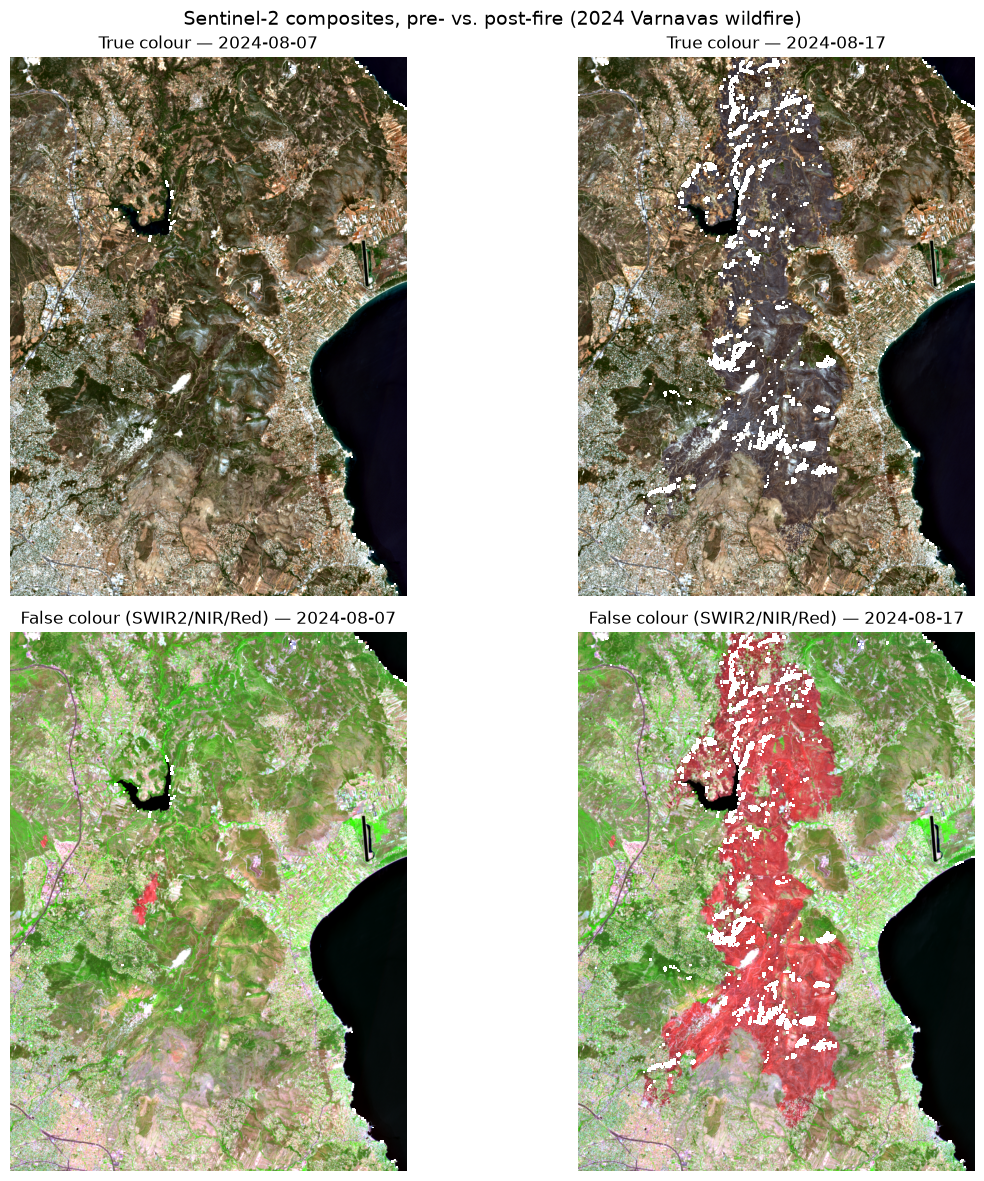

Saved: ../outputs/figures/rgb_false_color_pre_post.png


In [23]:
PRE_FIRE_IMAGE_DATE = "2024-08-07"
POST_FIRE_IMAGE_DATE = "2024-08-17"

FIGURES_DIR = Path("../outputs/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def make_composite(da, date, bands, low_pct=2, high_pct=98):
    """Build an (H, W, 3) uint8 RGB array from 3 reflectance bands via a
    per-band percentile stretch. NaN (masked) pixels become fully
    transparent in the returned alpha channel."""
    sel = da.sel(time=date, band=bands).transpose("y", "x", "band").compute()
    values = sel.values.astype("float32")

    rgb = np.zeros_like(values, dtype="float32")
    for i in range(3):
        band_vals = values[:, :, i]
        finite = band_vals[np.isfinite(band_vals)]
        lo, hi = np.percentile(finite, [low_pct, high_pct])
        rgb[:, :, i] = np.clip((band_vals - lo) / (hi - lo + 1e-9), 0, 1)

    alpha = np.isfinite(values).all(axis=-1).astype("float32")
    rgba = np.dstack([rgb, alpha])
    return rgba


fig, axes = plt.subplots(2, 2, figsize=(13, 12))

for col, date in enumerate([PRE_FIRE_IMAGE_DATE, POST_FIRE_IMAGE_DATE]):
    true_color = make_composite(reflectance_masked, date, ["B04", "B03", "B02"])
    false_color = make_composite(reflectance_masked, date, ["B12", "B08", "B04"])

    axes[0, col].imshow(true_color)
    axes[0, col].set_title(f"True colour — {date}")
    axes[0, col].axis("off")

    axes[1, col].imshow(false_color)
    axes[1, col].set_title(f"False colour (SWIR2/NIR/Red) — {date}")
    axes[1, col].axis("off")

fig.suptitle("Sentinel-2 composites, pre- vs. post-fire (2024 Varnavas wildfire)", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "rgb_false_color_pre_post.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved: {FIGURES_DIR / 'rgb_false_color_pre_post.png'}")

## 10. Spectral Indices: NDVI and NBR

Two spectral indices are computed for each acquisition from the scaled and SCL-masked reflectance data:

- **NDVI (Normalized Difference Vegetation Index):** `(B08 - B04) / (B08 + B04)`, using NIR and red reflectance to characterise vegetation greenness.
- **NBR (Normalized Burn Ratio):** `(B08 - B12) / (B08 + B12)`, using NIR and SWIR2 reflectance to highlight spectral changes associated with vegetation loss and fire disturbance.

Negative retrieved reflectance values are preserved in the calibrated reflectance data, but pixels where either input band is negative are excluded from the normalized-difference calculation. This avoids unstable or out-of-range ratios caused by sign-changing or near-zero denominators without modifying the underlying reflectance values.

Pixels already removed by the SCL quality mask remain `NaN`.

In [24]:
def normalized_difference(da, band_a, band_b):
    a = da.sel(band=band_a, drop=True)
    b = da.sel(band=band_b, drop=True)

    valid = (a >= 0) & (b >= 0) & ((a + b) > 0)

    return ((a - b) / (a + b)).where(valid)


ndvi = normalized_difference(reflectance_masked, "B08", "B04")
ndvi.name = "NDVI"

nbr = normalized_difference(reflectance_masked, "B08", "B12")
nbr.name = "NBR"

print("NDVI dims/shape:", ndvi.dims, ndvi.shape)
print("NBR dims/shape:", nbr.dims, nbr.shape)
print("Any +/-inf remaining in NDVI:", bool(np.isinf(ndvi.fillna(0)).any()))
print("Any +/-inf remaining in NBR:", bool(np.isinf(nbr.fillna(0)).any()))

NDVI dims/shape: ('time', 'y', 'x') (8, 1307, 962)
NBR dims/shape: ('time', 'y', 'x') (8, 1307, 962)
Any +/-inf remaining in NDVI: False
Any +/-inf remaining in NBR: False


## 11. Temporal Analysis: NDVI/NBR Time Series

The AOI-mean of each index is computed per acquisition (NaN-skipping, so masked-out pixels don't bias the mean) across all 8 dates, and plotted against time with the fire date marked. This is the direct evidence for "did vegetation/burn signal actually change here, and when" — the qualitative pattern expected is a sharp NBR (and to a lesser extent NDVI) drop between the last pre-fire and first post-fire acquisition, with limited pre-fire drift.

In [25]:
ndvi_mean = ndvi.mean(dim=["y", "x"], skipna=True).compute()
nbr_mean = nbr.mean(dim=["y", "x"], skipna=True).compute()

timeseries_df = pd.DataFrame({
    "date": pd.to_datetime(ndvi["time"].values),
    "NDVI_mean": ndvi_mean.values,
    "NBR_mean": nbr_mean.values,
}).sort_values("date").reset_index(drop=True)

timeseries_df

,date,NDVI_mean,NBR_mean
0,2024-07-13,0.328833,0.113774
1,2024-07-23,0.323703,0.103086
2,2024-08-02,0.334889,0.129574
3,2024-08-07,0.334061,0.126898
4,2024-08-17,0.259571,0.015634
5,2024-08-22,0.279837,0.000931
6,2024-09-06,0.276047,0.015627
7,2024-09-26,0.281055,0.018438


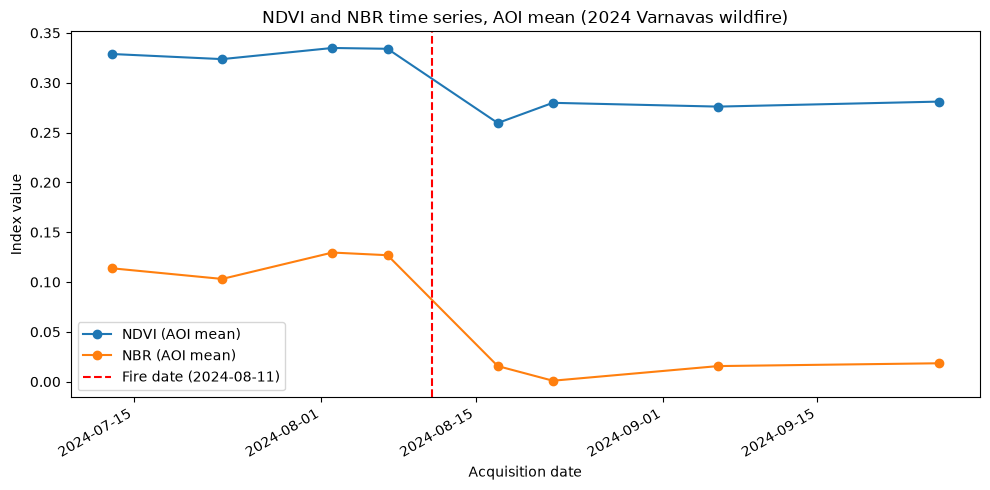

Saved: ../outputs/figures/ndvi_nbr_timeseries.png


In [26]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(timeseries_df["date"], timeseries_df["NDVI_mean"], marker="o", label="NDVI (AOI mean)")
ax.plot(timeseries_df["date"], timeseries_df["NBR_mean"], marker="o", label="NBR (AOI mean)")
ax.axvline(FIRE_DATE, color="red", linestyle="--", label=f"Fire date ({FIRE_DATE.date()})")

ax.set_xlabel("Acquisition date")
ax.set_ylabel("Index value")
ax.set_title("NDVI and NBR time series, AOI mean (2024 Varnavas wildfire)")
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "ndvi_nbr_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved: {FIGURES_DIR / 'ndvi_nbr_timeseries.png'}")

## 12. Pre-Fire and Post-Fire NBR Composites

A single pre/post image pair would be sensitive to residual noise or masking artefacts in a specific acquisition. Instead, per-pixel **medians** are computed across the 4 pre-fire and 4 post-fire acquisitions:

- **Pre-fire composite:** median NBR over `2024-07-13, 2024-07-23, 2024-08-02, 2024-08-07`.
- **Post-fire composite:** median NBR over `2024-08-17, 2024-08-22, 2024-09-06, 2024-09-26`.

The median is used because it is less sensitive than the mean to occasional per-pixel outliers that may remain after SCL masking. The six-week post-fire window provides multiple observations for a more robust post-fire composite, although genuine vegetation change during this period may also influence the resulting NBR and is therefore treated as a limitation.

In [27]:
PRE_FIRE_DATES = pd.to_datetime(["2024-07-13", "2024-07-23", "2024-08-02", "2024-08-07"])
POST_FIRE_DATES = pd.to_datetime(["2024-08-17", "2024-08-22", "2024-09-06", "2024-09-26"])

assert set(PRE_FIRE_DATES) | set(POST_FIRE_DATES) == set(pd.to_datetime(SELECTED_DATES))
assert all(d < FIRE_DATE for d in PRE_FIRE_DATES)
assert all(d > FIRE_DATE for d in POST_FIRE_DATES)

nbr_pre = nbr.sel(time=PRE_FIRE_DATES).median(dim="time", skipna=True)
nbr_post = nbr.sel(time=POST_FIRE_DATES).median(dim="time", skipna=True)

nbr_pre.name = "NBR_pre_composite"
nbr_post.name = "NBR_post_composite"

print("nbr_pre dims/shape:", nbr_pre.dims, nbr_pre.shape)
print("nbr_post dims/shape:", nbr_post.dims, nbr_post.shape)

nbr_pre dims/shape: ('y', 'x') (1307, 962)
nbr_post dims/shape: ('y', 'x') (1307, 962)


## 13. dNBR and Burn Severity Classification

**dNBR = NBR_pre − NBR_post.** Because NBR typically decreases following fire-related vegetation loss and surface change, positive dNBR values generally indicate a stronger post-fire spectral change.

Classification uses the reference dNBR ranges presented by Key & Benson (2006) in the USDA Forest Service FIREMON protocol:

| Class | dNBR range |
|---|---|
| High regrowth | −0.500 to −0.251 |
| Low regrowth | −0.250 to −0.101 |
| Unburned | −0.100 to 0.099 |
| Low severity | 0.100 to 0.269 |
| Moderate-low severity | 0.270 to 0.439 |
| Moderate-high severity | 0.440 to 0.659 |
| High severity | 0.660 to 1.300 |

The original FIREMON ranges are expressed as dNBR × 1000; the values above are shown in the native dNBR scale used in this notebook. These ranges are treated as a reference classification rather than universal thresholds, since their interpretation can vary between scene pairs and ecosystems.

**Limitations:**
- dNBR is a spectral proxy for burn severity rather than a direct ecological measurement. Field observations such as Composite Burn Index (CBI) measurements would be required for local validation.
- The reference thresholds were developed primarily using North American fire environments and are not locally calibrated for Mediterranean vegetation in Attica.
- The post-fire composite spans approximately six weeks, so genuine vegetation change during this period may influence the resulting dNBR.

In [28]:
dnbr = nbr_pre - nbr_post
dnbr.name = "dNBR"
dnbr = dnbr.rio.write_crs(f"EPSG:{TARGET_EPSG}")

SEVERITY_BINS = [-0.500, -0.251, -0.101, 0.099, 0.269, 0.439, 0.659, 1.300]

SEVERITY_LABELS = [
    "High regrowth",
    "Low regrowth",
    "Unburned",
    "Low severity",
    "Moderate-low severity",
    "Moderate-high severity",
    "High severity",
]

dnbr_computed = dnbr.compute()

valid_reference_range = (
    np.isfinite(dnbr_computed)
    & (dnbr_computed >= SEVERITY_BINS[0])
    & (dnbr_computed <= SEVERITY_BINS[-1])
)

severity_codes = xr.apply_ufunc(
    lambda x: np.digitize(x, SEVERITY_BINS[1:-1]),
    dnbr_computed,
    dask="parallelized" if dnbr_computed.chunks else "allowed",
    output_dtypes=[np.int8],
)

severity_codes = severity_codes.where(valid_reference_range)
severity_codes.name = "severity_class"
severity_codes = severity_codes.rio.write_crs(f"EPSG:{TARGET_EPSG}")

print("dNBR computed. Non-NaN pixels:", int((~np.isnan(dnbr_computed)).sum()))
print("dNBR range:", float(np.nanmin(dnbr_computed)), "to", float(np.nanmax(dnbr_computed)))

outside_reference = (
    np.isfinite(dnbr_computed) & ~valid_reference_range
).sum().item()

outside_pct = 100 * outside_reference / int(np.isfinite(dnbr_computed).sum())

print(
    f"Pixels outside reference classification range: "
    f"{outside_reference} ({outside_pct:.3f}%)"
)

dNBR computed. Non-NaN pixels: 1232083
dNBR range: -1.526577353477478 to 1.1947649717330933
Pixels outside reference classification range: 88 (0.007%)


In [29]:
severity_values = severity_codes.values
valid = ~np.isnan(severity_values)
codes, counts = np.unique(severity_values[valid].astype(int), return_counts=True)

pixel_area_ha = (abs(dnbr_computed.rio.resolution()[0]) * abs(dnbr_computed.rio.resolution()[1])) / 1e4

severity_summary = pd.DataFrame({
    "class": [SEVERITY_LABELS[c] for c in codes],
    "pixel_count": counts,
    "area_ha": counts * pixel_area_ha,
})
severity_summary["pct_of_valid_area"] = 100 * severity_summary["pixel_count"] / severity_summary["pixel_count"].sum()
severity_summary = severity_summary.sort_values("pixel_count", ascending=False).reset_index(drop=True)
severity_summary

,class,pixel_count,area_ha,pct_of_valid_area
0,Unburned,883774,35350.96,71.735194
1,Moderate-high severity,115751,4630.04,9.395412
2,Low severity,92363,3694.52,7.497027
3,Moderate-low severity,78121,3124.84,6.341016
4,High severity,57099,2283.96,4.634678
5,Low regrowth,4036,161.44,0.327599
6,High regrowth,851,34.04,0.069075


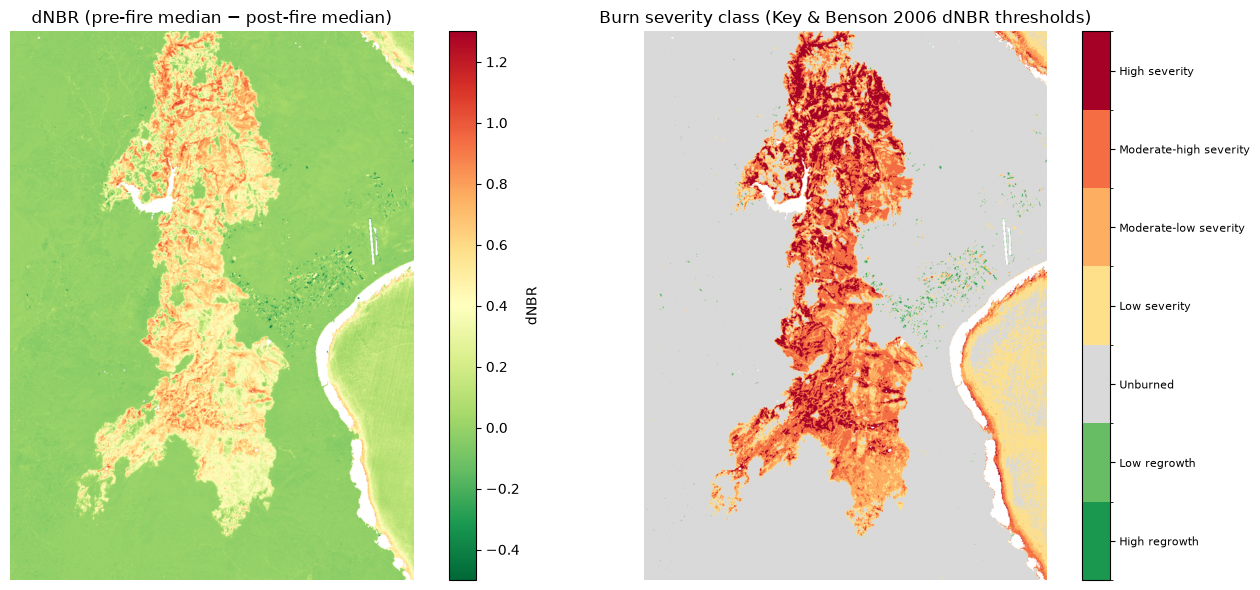

Saved: ../outputs/figures/dnbr_severity_map.png


In [30]:
from matplotlib.colors import BoundaryNorm, ListedColormap

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

im0 = axes[0].imshow(dnbr_computed.values, cmap="RdYlGn_r", vmin=-0.5, vmax=1.3)
axes[0].set_title("dNBR (pre-fire median − post-fire median)")
axes[0].axis("off")
fig.colorbar(im0, ax=axes[0], fraction=0.04, label="dNBR")

severity_cmap = ListedColormap([
    "#1a9850", "#66bd63", "#d9d9d9", "#fee08b", "#fdae61", "#f46d43", "#a50026",
])
norm = BoundaryNorm(np.arange(-0.5, 7.5), severity_cmap.N)
im1 = axes[1].imshow(severity_codes.values, cmap=severity_cmap, norm=norm)
axes[1].set_title("Burn severity class (Key & Benson 2006 dNBR thresholds)")
axes[1].axis("off")
cbar = fig.colorbar(im1, ax=axes[1], ticks=range(7), fraction=0.04)
cbar.ax.set_yticklabels(SEVERITY_LABELS, fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "dnbr_severity_map.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved: {FIGURES_DIR / 'dnbr_severity_map.png'}")

## 14. Georeferenced Raster Export

The continuous dNBR layer and the classified burn-severity layer are exported as georeferenced rasters in the analysis CRS (EPSG:32634).

Cloud-Optimized GeoTIFF (COG) is used when supported by the installed GDAL build, with a tiled GeoTIFF fallback otherwise. Lossless DEFLATE compression is applied in both cases.

After export, each raster is reopened with Rasterio to verify its CRS, dimensions, and NoData value.

In [31]:
RASTERS_DIR = Path("../outputs/rasters")
RASTERS_DIR.mkdir(parents=True, exist_ok=True)


def export_raster(da, path, dtype, nodata):
    out = da.astype(dtype).rio.write_nodata(nodata)
    try:
        out.rio.to_raster(path, driver="COG", compress="deflate")
    except Exception as exc:
        print(f"COG driver unavailable ({exc!r}), falling back to tiled GeoTIFF.")
        out.rio.to_raster(path, driver="GTiff", tiled=True, compress="deflate")


dnbr_path = RASTERS_DIR / "dnbr.tif"
severity_path = RASTERS_DIR / "burn_severity_class.tif"

export_raster(dnbr_computed.fillna(np.nan), dnbr_path, "float32", np.nan)
export_raster(severity_codes.fillna(-1), severity_path, "int8", -1)

print("Wrote:", dnbr_path)
print("Wrote:", severity_path)

with rasterio.open(dnbr_path) as src:
    print("\ndNBR raster check -> CRS:", src.crs, "shape:", src.shape, "nodata:", src.nodata)

with rasterio.open(severity_path) as src:
    print("Severity raster check -> CRS:", src.crs, "shape:", src.shape, "nodata:", src.nodata)

Wrote: ../outputs/rasters/dnbr.tif
Wrote: ../outputs/rasters/burn_severity_class.tif

dNBR raster check -> CRS: EPSG:32634 shape: (1307, 962) nodata: nan
Severity raster check -> CRS: EPSG:32634 shape: (1307, 962) nodata: -1.0


## 15. Vector Output: Priority-Severity Polygons

Pixels classified as **moderate-high** or **high** severity (dNBR ≥ 0.440) are combined into a binary priority mask and vectorised into contiguous polygons using `rasterio.features.shapes`.

Polygon areas are calculated in the projected analysis CRS (EPSG:32634), and regions smaller than 0.5 ha are removed to avoid retaining very small fragmented areas in the final decision layer. Mean dNBR is also calculated for each polygon to retain information about the magnitude of spectral change within each mapped region.

For GeoJSON export, the resulting vector layer is reprojected to WGS84 (EPSG:4326), while the metric calculations remain based on EPSG:32634.

In [32]:
PRIORITY_SEVERITY_CODES = [5, 6]  # moderate-high and high severity

# Binary mask of the severity classes retained for the priority layer.
priority_mask_bool = np.isin(
    severity_codes.values,
    PRIORITY_SEVERITY_CODES,
)
priority_mask = priority_mask_bool.astype("uint8")

transform = dnbr_computed.rio.transform()

# Convert contiguous priority pixels into polygons.
polygons = []
for geom, _ in rio_shapes(
    priority_mask,
    mask=priority_mask_bool,
    transform=transform,
):
    polygons.append(shapely_shape(geom))

burned_gdf = gpd.GeoDataFrame(
    {"geometry": polygons},
    crs=f"EPSG:{TARGET_EPSG}",
)

# EPSG:32634 uses metres, so 1 ha = 10,000 m².
burned_gdf["area_ha"] = burned_gdf.geometry.area / 1e4

# Calculate mean dNBR within each polygon.
mean_dnbr = []

for geom in burned_gdf.geometry:
    clipped = dnbr_computed.rio.clip(
        [geom],
        all_touched=False,
        drop=True,
    )
    mean_dnbr.append(float(np.nanmean(clipped.values)))

burned_gdf["mean_dnbr"] = mean_dnbr

# Remove polygons without a finite dNBR value and very small fragmented
# priority polygons (<0.5 ha).
burned_gdf = burned_gdf[
    burned_gdf["mean_dnbr"].notna()
].copy()

burned_gdf = burned_gdf[
    burned_gdf["area_ha"] >= 0.5
].reset_index(drop=True)

print(
    f"Vectorised {len(burned_gdf)} moderate-high/high severity "
    f"priority polygons (>=0.5 ha)."
)

burned_gdf.head()

Vectorised 201 moderate-high/high severity priority polygons (>=0.5 ha).


,geometry,area_ha,mean_dnbr
0,"POLYGON ((754410 4236810, 754410 4236770, 7543...",0.56,0.499271
1,"POLYGON ((763570 4236810, 763570 4236770, 7635...",5.96,0.568548
2,"POLYGON ((764370 4236810, 764370 4236790, 7643...",5.28,0.579466
3,"POLYGON ((763830 4236610, 763830 4236570, 7638...",1.84,0.535651
4,"POLYGON ((764090 4236530, 764090 4236510, 7641...",2.24,0.575013


In [33]:
VECTORS_DIR = Path("../outputs/vectors")
VECTORS_DIR.mkdir(parents=True, exist_ok=True)

burned_gdf_wgs84 = burned_gdf.to_crs("EPSG:4326")
burned_areas_path = VECTORS_DIR / "burned_areas_moderate_high_severity.geojson"
burned_gdf_wgs84.to_file(burned_areas_path, driver="GeoJSON")

print(f"Wrote {len(burned_gdf_wgs84)} polygons to {burned_areas_path}")

# Verify: reopen and confirm CRS + geometry validity.
check_gdf = gpd.read_file(burned_areas_path)
print("Reopened CRS:", check_gdf.crs)
print("All geometries valid:", check_gdf.geometry.is_valid.all())
print("Total mapped priority-severity area (ha):", burned_gdf["area_ha"].sum().round(1))

Wrote 201 polygons to ../outputs/vectors/burned_areas_moderate_high_severity.geojson
Reopened CRS: EPSG:4326
All geometries valid: True
Total mapped priority-severity area (ha): 6775.9


## 16. Decision Intelligence

**Decision question:** Which areas affected by the August 2024 Varnavas wildfire experienced the greatest vegetation damage and should be prioritised for post-fire field assessment?

**Users:** forest-management and environmental-restoration authorities planning field inspections and recovery actions.

**Rule:** contiguous moderate-high/high-severity polygons (dNBR ≥ 0.440, ≥ 0.5 ha) are ranked using a simple **severity-weighted extent** score:

`priority_score = area_ha × mean_dnbr`

This transparent rule accounts for both the spatial extent of each mapped area and the magnitude of its mean spectral change. It is used here as a practical prioritisation rule rather than as an established burn-severity metric.

The outputs are a ranked table, a GeoJSON containing the same polygons and their priority attributes, and a short plain-language decision summary.

In [34]:
priority_gdf = burned_gdf[np.isfinite(burned_gdf["mean_dnbr"])].copy()  # guard: exclude any non-finite residue
priority_gdf["priority_score"] = priority_gdf["area_ha"] * priority_gdf["mean_dnbr"]
priority_gdf = priority_gdf.sort_values("priority_score", ascending=False).reset_index(drop=True)
priority_gdf["rank"] = priority_gdf.index + 1

# Centroid computed in the projected (metric) CRS, then reprojected to WGS84
# for a human-readable location.
centroids_wgs84 = priority_gdf.geometry.centroid.to_crs("EPSG:4326")
priority_gdf["centroid_lon"] = centroids_wgs84.x.round(4)
priority_gdf["centroid_lat"] = centroids_wgs84.y.round(4)

priority_table = priority_gdf[["rank", "area_ha", "mean_dnbr", "priority_score", "centroid_lon", "centroid_lat"]].head(10)
priority_table

,rank,area_ha,mean_dnbr,priority_score,centroid_lon,centroid_lat
0,1,5663.40,0.630295,3569.614945,23.9201,38.1482
1,2,119.24,0.555918,66.287653,24.0136,38.0335
2,3,123.52,0.535484,66.142941,23.9222,38.0612
3,4,98.92,0.570268,56.410908,23.9400,38.0635
4,5,56.56,0.646874,36.587177,23.8784,38.0777
5,6,51.36,0.664950,34.151830,23.8776,38.1804
6,7,48.72,0.554424,27.011528,23.9970,38.0784
7,8,35.40,0.661405,23.413727,23.8811,38.1872
8,9,42.20,0.520896,21.981812,23.9341,38.0818
9,10,30.40,0.686493,20.869383,23.8937,38.1931


In [35]:
priority_areas_path = VECTORS_DIR / "priority_areas_ranked.geojson"
priority_gdf.to_crs("EPSG:4326").to_file(priority_areas_path, driver="GeoJSON")
print(f"Wrote {len(priority_gdf)} ranked priority-area polygons to {priority_areas_path}")

total_priority_ha = burned_gdf["area_ha"].sum()
n_priority = len(priority_gdf)
top = priority_gdf.iloc[0]

summary_text = f"""
DECISION SUMMARY — 2024 Varnavas wildfire, Attica

Total mapped moderate-high/high-severity priority area: {total_priority_ha:.1f} ha,
across {n_priority} contiguous priority area(s) (>= 0.5 ha each).

Top-priority area for field assessment: rank 1, {top['area_ha']:.1f} ha,
with mean dNBR {top['mean_dnbr']:.3f}, centred at approximately
{top['centroid_lat']:.4f} N, {top['centroid_lon']:.4f} E.

Recommendation: field crews should consider priority areas in rank order
(see `priority_areas_ranked.geojson`), based on the combined mapped extent
and mean dNBR of each area.

Caveat: dNBR is a spectral proxy for burn severity, not validated ground
truth for this fire. The ranking should therefore be used as a field-
prioritisation aid rather than as a final severity determination.
""".strip()

print(summary_text)

with open(VECTORS_DIR / "decision_summary.txt", "w") as f:
    f.write(summary_text + "\n")

Wrote 201 ranked priority-area polygons to ../outputs/vectors/priority_areas_ranked.geojson
DECISION SUMMARY — 2024 Varnavas wildfire, Attica

Total mapped moderate-high/high-severity priority area: 6775.9 ha,
across 201 contiguous priority area(s) (>= 0.5 ha each).

Top-priority area for field assessment: rank 1, 5663.4 ha,
with mean dNBR 0.630, centred at approximately
38.1482 N, 23.9201 E.

Recommendation: field crews should consider priority areas in rank order
(see `priority_areas_ranked.geojson`), based on the combined mapped extent
and mean dNBR of each area.

Caveat: dNBR is a spectral proxy for burn severity, not validated ground
truth for this fire. The ranking should therefore be used as a field-
prioritisation aid rather than as a final severity determination.


## 17. Final Interactive Map

An interactive Folium map combining the AOI boundary and the ranked priority-area polygons (coloured by rank, most urgent in red), each with a popup giving its rank, area, and mean dNBR — directly usable by a non-technical stakeholder, and it opens correctly in any GeoJSON-aware viewer since the underlying files are standard WGS84 GeoJSON.

In [37]:
priority_wgs84 = priority_gdf.to_crs("EPSG:4326")

final_map = folium.Map(location=[center_lat, center_lon], zoom_start=11, tiles="OpenStreetMap")

folium.GeoJson(
    aoi.__geo_interface__,
    name="AOI",
    style_function=lambda f: {"color": "black", "weight": 2, "fillOpacity": 0.0, "dashArray": "5,5"},
).add_to(final_map)

max_rank = priority_wgs84["rank"].max()
for _, row in priority_wgs84.iterrows():
    t = (row["rank"] - 1) / max(max_rank - 1, 1)
    color = f"#{int(255):02x}{int(255 * t):02x}00"  # red (rank 1) -> orange/yellow (lower rank)
    folium.GeoJson(
        row.geometry.__geo_interface__,
        style_function=lambda f, color=color: {"color": color, "weight": 1, "fillColor": color, "fillOpacity": 0.6},
        tooltip=(
            f"Rank {row['rank']} | {row['area_ha']:.1f} ha | "
            f"mean dNBR {row['mean_dnbr']:.3f}"
        ),
    ).add_to(final_map)

folium.LayerControl().add_to(final_map)
final_map

## 18. Summary, Trade-offs, and Limitations

This notebook implements an end-to-end Sentinel-2 workflow for assessing the 2024 Varnavas wildfire. Eight acquisitions are combined across two MGRS tiles, aligned to a common 20 m EPSG:32634 grid, quality-masked using the Sentinel-2 SCL, and used to compute NDVI and NBR. Pre- and post-fire median NBR composites are then used to derive dNBR, map burn severity, and produce georeferenced raster and vector outputs. Moderate-high and high-severity regions are finally ranked to support post-fire field-assessment planning.

**Key methodological choices and limitations:**
- **EPSG:32634** is used as the analysis CRS because it covers most of the AOI; the eastern edge extends slightly into UTM zone 35N.
- Same-date MGRS tiles are combined using a **first-valid-pixel mosaic**, a simple approach appropriate for the limited tile overlap in this AOI.
- **Median pre-/post-fire composites** reduce sensitivity to residual single-date artefacts, although the six-week post-fire window may also capture genuine vegetation change.
- SCL classes `{4, 5, 6, 7}` are retained as observable surface pixels, while clouds, shadows, snow/ice, defective pixels, and NoData are excluded.
- The **Key & Benson (2006)** dNBR ranges are used as a reference classification rather than locally calibrated thresholds. dNBR remains a spectral proxy, and field observations would be required to validate ecological burn severity for this specific fire.
- The `area_ha × mean_dnbr` priority score is a transparent decision rule developed for this workflow, not an established burn-severity metric.

**Possible extensions:** validate the mapped fire effects against an independent reference product or field observations, assess classification accuracy, incorporate Sentinel-1 SAR as a complementary data source, and explore the optional foundation-model or MCP/LLM components after validating the core EO workflow.